---
title: "A well-specified linear regression model"
author: "Nguyen Thu Uyen Sarah - nguyet79"
output: html_document
---

In [12]:
library(car) # use vif function for multicollinearity detection
library(lmtest) # use bptest for homoscedasticity test
library(glmnet) # shrinked linear models

In [13]:
# Set default graphics parameters
set_plot_defaults <- function() {
    par(bg="white",
        col="black",
        col.axis="black",
        col.lab="black",
        col.main="black",
        col.sub="black",
        fg="black")
}


In [14]:
d <- read.csv("lreg_data.csv")


Call:
lm(formula = y ~ ., data = d)

Residuals:
     Min       1Q   Median       3Q      Max 
-228.093  -21.041    1.894   24.501  157.924 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 148.6082    51.0869   2.909 0.004061 ** 
x1           -0.3404     0.3662  -0.929 0.353880    
x2            0.5223     0.2599   2.010 0.045906 *  
x3           -0.4873     0.6532  -0.746 0.456665    
x4           -2.5976     0.7574  -3.429 0.000742 ***
x5            1.1959     0.5055   2.366 0.019004 *  
x6           -0.3778     1.8612  -0.203 0.839357    
x7           -0.0174     0.2389  -0.073 0.942005    
x8           -0.6565     0.4402  -1.491 0.137543    
x9            1.3295     0.5107   2.603 0.009973 ** 
x10           1.0228     0.2342   4.367 2.08e-05 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 50.29 on 189 degrees of freedom
Multiple R-squared:  0.5803,	Adjusted R-squared:  0.5581 
F-statistic: 26.13 on 10 


	studentized Breusch-Pagan test

data:  full_lm
BP = 34.971, df = 10, p-value = 0.0001263


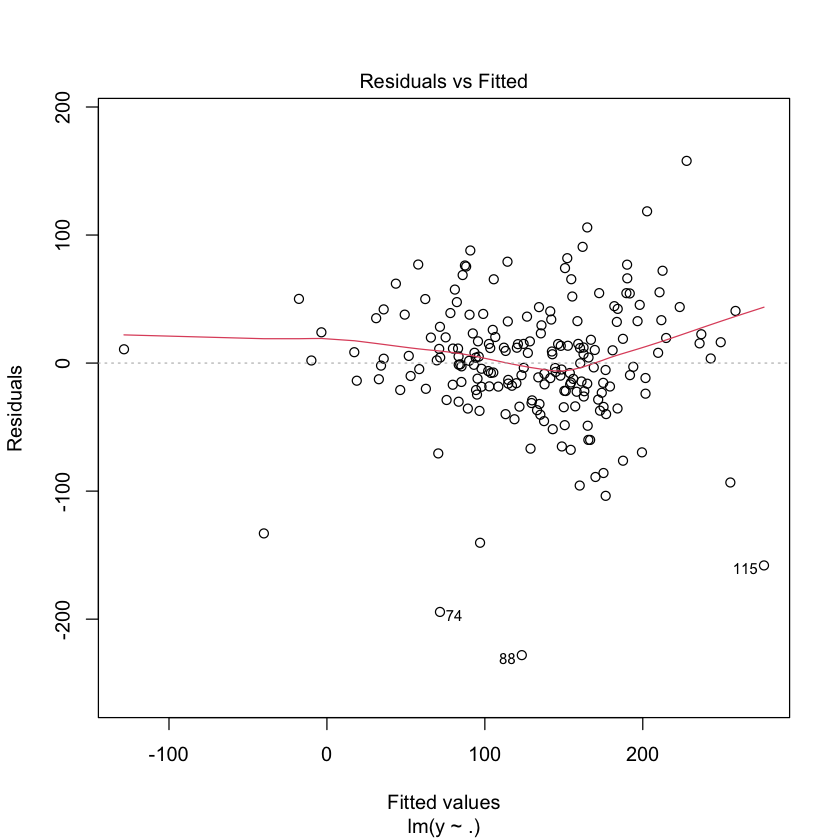


	Shapiro-Wilk normality test

data:  residuals(full_lm)
W = 0.93745, p-value = 1.384e-07


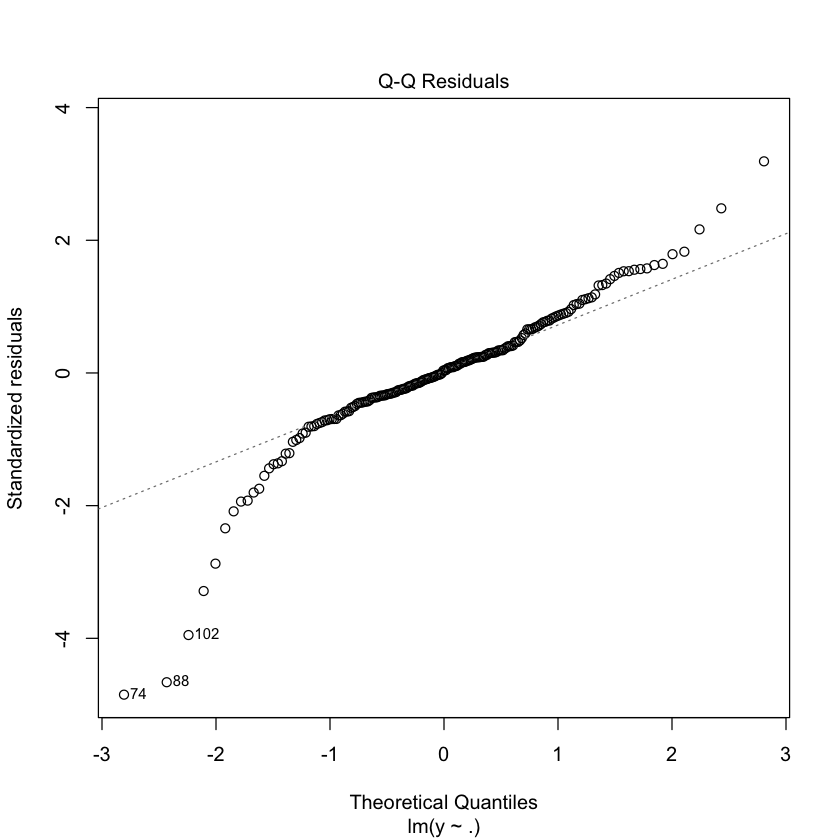

52  74  87  88  98 102 115 129 133 160 165 
 52  74  87  88  98 102 115 129 133 160 165

x1        x2        x3        x4        x5        x6        x7        x8 
 1.057418 10.268698  2.419465  2.143518 10.211986  1.032185  1.036711  1.541193 
       x9       x10 
 1.046448  1.050156

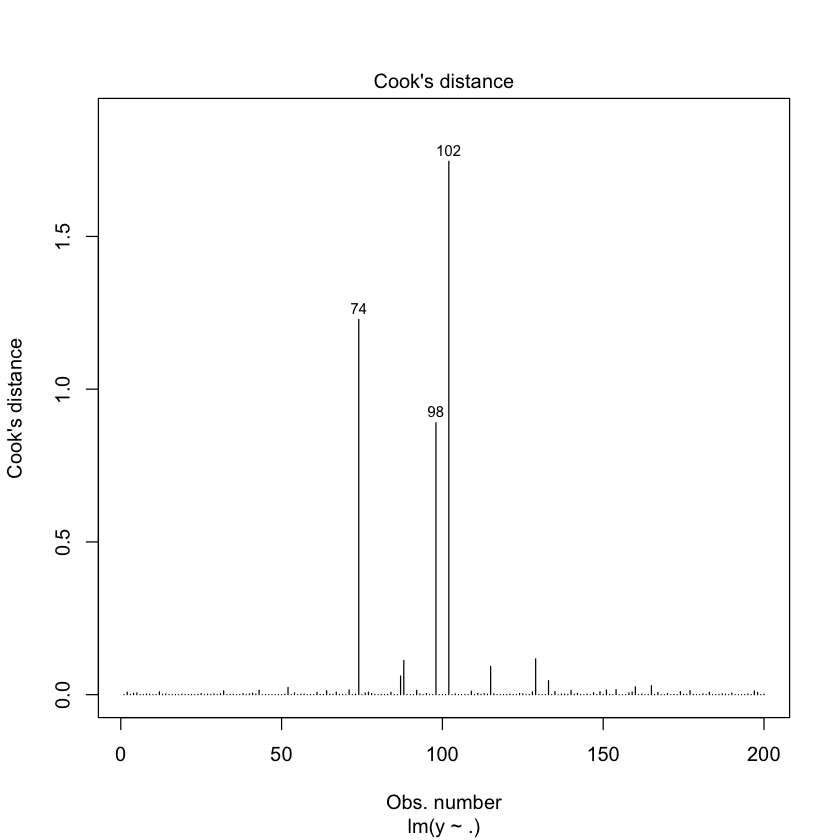

In [15]:
full_lm <- lm(y ~ ., d)
summary(full_lm)

# check for the issues
set_plot_defaults()
# start with the residual plot
plot(full_lm, which=1)

# perform a homoscedasticity test
bptest(full_lm)

# normality of residuals? Q-Q plot and normality test
plot(full_lm, which = 2)  
shapiro.test(residuals(full_lm))

# search for outliers
plot(full_lm, which = 4)
which(cooks.distance(full_lm) > 4 / (nrow(d) - length(coef(full_lm))))

# detect potential multicollinearity
vif(full_lm)

ISSUES: - there are issues with linearity 
        1) heteroscedasticity: according to Breusch-Pagan test: p-value is 0.0001263  which means that it is significant p<0.05 which means that we can reject homoscedasticity in favor of heteroscedasticity. We can see this in the "Residuals vs Fitted" plot. 
        2) normality test: issue with the normality of residuals. According to Shapiro-Wilk test which sets the p value below 0.05 which indicates that the residuals are not normally distributed. We can see this in the QQ plot as well. The ends are "turned" which means that there are more extreme values than a normal distribution. 
        3) Issue with outliers: we can gain insight on the outliers in the dataset with Cook's distance. We can see that there are 3 major outliers with cook's distance more than approximately 0.9 which indicates that these point have high levarage and are significantly affecting the regression estimates.
        4) Issue with multicollinearity -> vif value is >10 in x2 and x5 this indicates that there are problems with multicollinearity ->unstable coefficients and unreliable coefficient estimates


Now deal with the detected issues in the right order. Build an alternative model and show that it works better than the full model. Finally, verbally justify all the decisions that you made and explain their effects.


In [27]:
#1 Remove the outliers
outlier_threshold <- 4 / (nrow(d) - length(coef(full_lm)))
outliers <- which(cooks.distance(full_lm) > outlier_threshold)

if(length(outliers) > 0) {
    d_clean <- d[-outliers, ]
} else {
    d_clean <- d
}


full_lm2 <- lm(formula(full_lm), data = d_clean)

outlier_threshold2 <- 4 / (nrow(d_clean) - length(coef(full_lm2)))
outliers2 <- which(cooks.distance(full_lm2) > outlier_threshold2)
if(length(outliers2) > 0) {
    d_clean2 <- d_clean[-outliers2, ]
} else {
    d_clean2 <- d_clean
}

In [28]:
#2 REfit the model without outliers
clean_lm <- lm(y ~ ., d_clean2)
summary(clean_lm)


Call:
lm(formula = y ~ ., data = d_clean2)

Residuals:
    Min      1Q  Median      3Q     Max 
-86.255 -18.351  -0.406  20.407  81.123 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 103.78134   40.69301   2.550 0.011671 *  
x1           -0.51184    0.22908  -2.234 0.026805 *  
x2            0.24744    0.21413   1.156 0.249539    
x3            3.91607    0.81232   4.821 3.22e-06 ***
x4            0.88775    0.74607   1.190 0.235794    
x5            1.74443    0.42684   4.087 6.81e-05 ***
x6           -0.95320    1.19342  -0.799 0.425603    
x7            0.04953    0.14528   0.341 0.733601    
x8           -1.40200    0.39005  -3.594 0.000429 ***
x9            0.58164    0.33064   1.759 0.080407 .  
x10           0.15620    0.20165   0.775 0.439668    
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 29.09 on 165 degrees of freedom
Multiple R-squared:  0.7984,	Adjusted R-squared:  0.7862 
F-statistic: 65.


	Shapiro-Wilk normality test

data:  residuals(clean_lm)
W = 0.99658, p-value = 0.9632


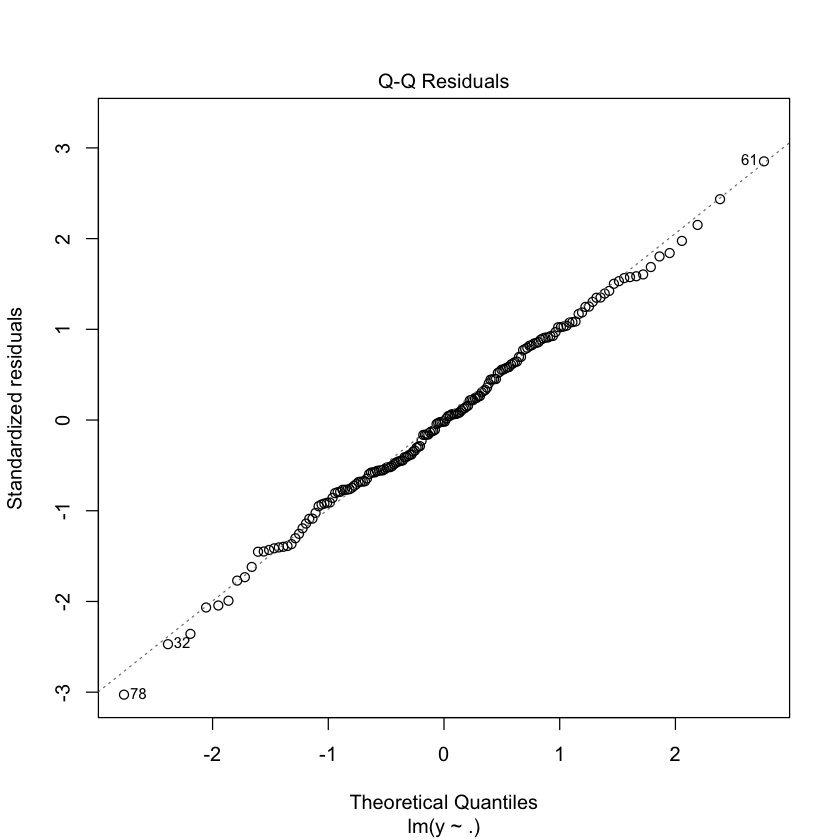

In [29]:
set_plot_defaults()
plot(clean_lm, which = 2)  
shapiro.test(residuals(clean_lm))

In [30]:
d_clean3 <- d_clean2
high_vif <- TRUE

while(high_vif) {
    vif_values <- vif(clean_lm)
    max_vif <- max(vif_values)
    
    if(max_vif > 10) {
        var_to_remove <- names(which.max(vif_values))
        d_clean3 <- d_clean3[, !(names(d_clean3) %in% var_to_remove)]
        clean_lm <- lm(y ~ ., d_clean3)
    } else {
        high_vif <- FALSE
    }
}


In [31]:
improved_model <- lm(y ~ ., d_clean3)
summary(improved_model)




Call:
lm(formula = y ~ ., data = d_clean3)

Residuals:
    Min      1Q  Median      3Q     Max 
-80.288 -20.988  -0.681  19.216  92.159 

Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 173.62987   38.63718   4.494 1.31e-05 ***
x1           -0.51436    0.23967  -2.146   0.0333 *  
x2            1.09752    0.05321  20.627  < 2e-16 ***
x3            3.61187    0.84629   4.268 3.31e-05 ***
x4            0.61771    0.77749   0.794   0.4280    
x6           -1.77817    1.23060  -1.445   0.1504    
x7            0.12288    0.15083   0.815   0.4164    
x8           -2.09259    0.36780  -5.689 5.64e-08 ***
x9            0.55206    0.34584   1.596   0.1123    
x10           0.41377    0.20040   2.065   0.0405 *  
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 30.43 on 166 degrees of freedom
Multiple R-squared:  0.778,	Adjusted R-squared:  0.7659 
F-statistic: 64.63 on 9 and 166 DF,  p-value: < 2.2e-16



	studentized Breusch-Pagan test

data:  improved_model
BP = 20.577, df = 9, p-value = 0.01467


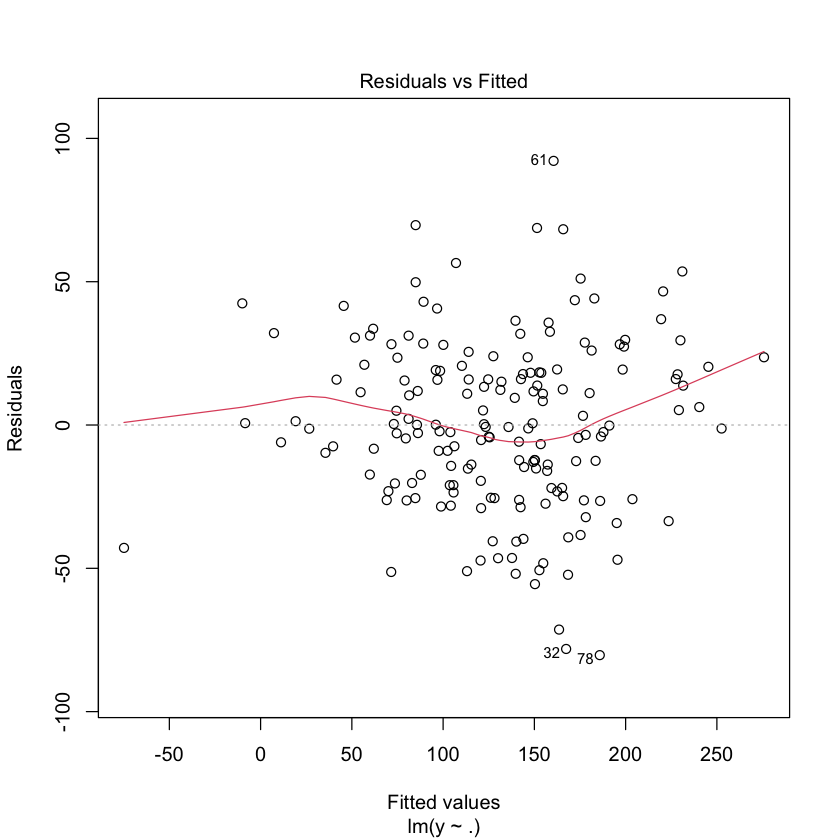


	Shapiro-Wilk normality test

data:  residuals(improved_model)
W = 0.99532, p-value = 0.859


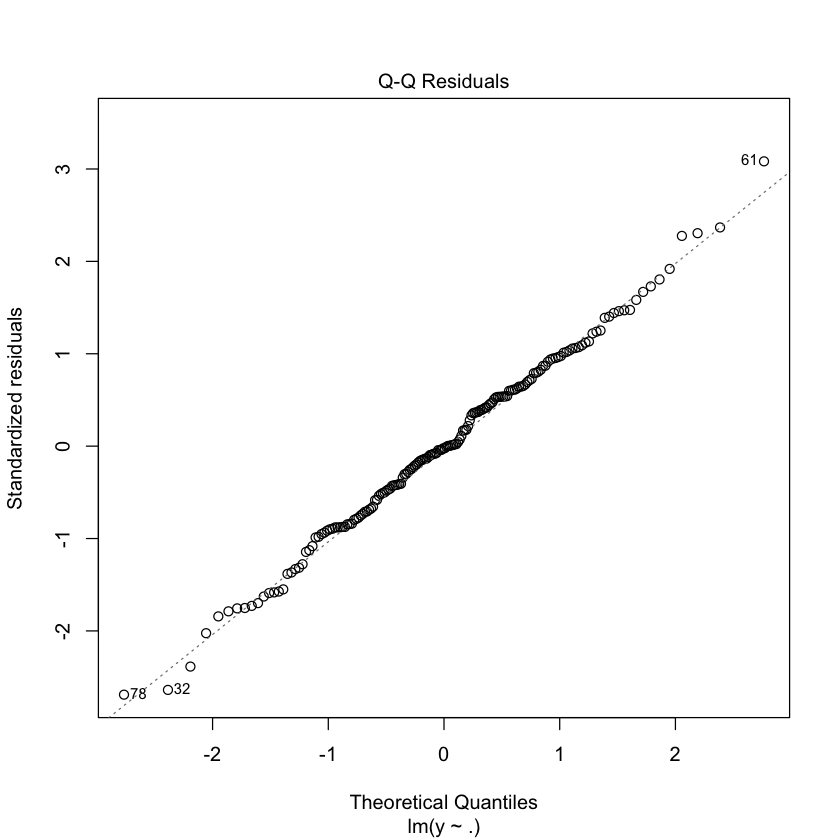

32  61  64  71  78 103 111 149 159 167 
 30  57  60  67  73  93 100 132 141 147

x1       x2       x3       x4       x6       x7       x8       x9 
1.058353 1.020449 4.747637 4.763182 1.034743 1.046610 1.160927 1.069841 
     x10 
1.118491

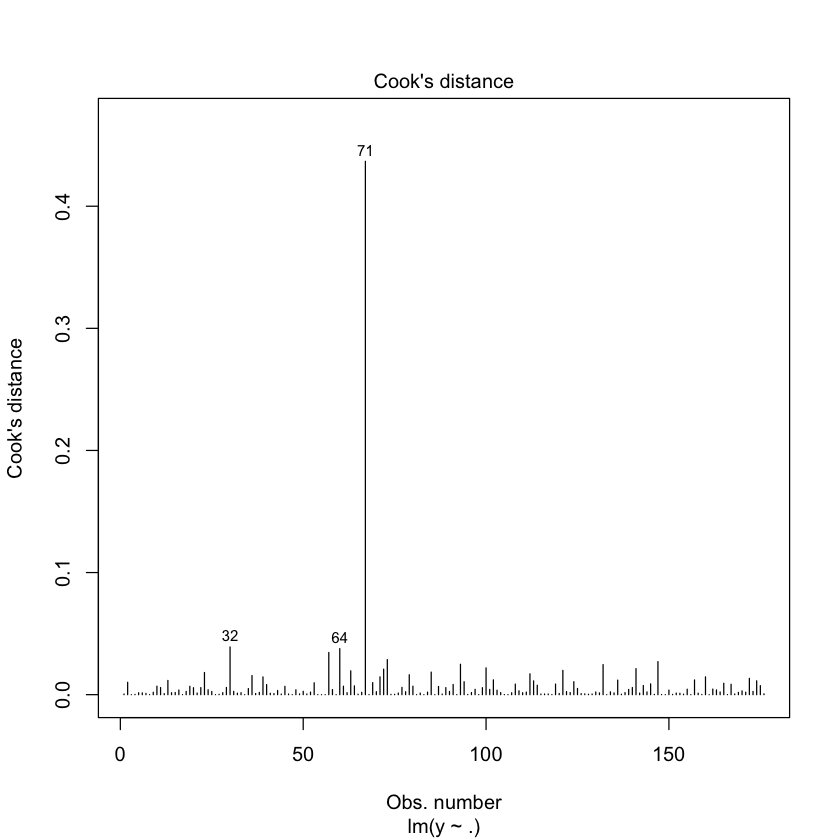

In [32]:


# check for the issues
set_plot_defaults()
# start with the residual plot
plot(improved_model, which=1)

# perform a homoscedasticity test
bptest(improved_model)

# normality of residuals? Q-Q plot and normality test
plot(improved_model, which = 2)  
shapiro.test(residuals(improved_model))

# search for outliers
plot(improved_model, which = 4)
which(cooks.distance(improved_model) > 4 / (nrow(d) - length(coef(improved_model))))

# detect potential multicollinearity
vif(improved_model)

The goal now is to perform feature selection and remove irrelevant variables. Compare several different feature selection methods and choose the most appropriate one. Demonstrate that applying feature selection to the full model yields very different results compared to applying it to an alternative model without issues. Finally, explain the selected model.
